<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/statistics/index.html">Statistics</a><span class="sep">·</span>Part 2 · Comparing two samples</p><p class="mh-facts"><span class="lvl lvl-introductory">Introductory</span></p><p class="mh-assumes">School maths. Python or R for the notebooks.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A two-sample t-test divides the difference between two group means by its standard error: how far apart the means are, in units of how far apart chance alone would put them. Use Welch's version by default. In simulations with no true difference, Student's equal-variance version gives 26.8% false positives when the smaller group is the noisier one, against 5.3% for Welch, and Welch costs almost nothing when variances are equal. When measurements come in pairs, test the differences: with a correlation of 0.8 between the halves of each field, the paired test detects a real effect 60.6% of the time and the unpaired test 6.1%. Independence is the assumption that breaks most analyses: counting 10 berries from each of 5 bushes per treatment as separate replicates gives 42.4% false positives when nothing differs. Outliers mostly cost power. In practice: count your independent units first, then run Welch.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C = fallcolor.palette.discrete("default")

rng = np.random.default_rng(1947)
REPS, ALPHA = 20_000, 0.05


def share_sig(p):  # share of simulated experiments with p < 0.05
    return np.mean(p < ALPHA)

Is the difference between two treatments, cultivars or packing lines real, or the kind of gap two samples show by chance? This module builds the t-test from [Variance and standard error](../variance-and-standard-error.qmd) and spends most of its time on where the default goes wrong; what its p-value means is in [What a p-value is not](../p-values/what_a_p_value_is_not.ipynb). All data are synthetic, from a fixed seed.

## A difference over its standard error

The statistic measures the observed gap in units of the gap expected from noise. For two independent groups,

$$t = \frac{\bar{y}_1 - \bar{y}_2}{\mathrm{SE}}, \qquad \mathrm{SE} = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$$

where $\bar{y}_1, \bar{y}_2$ are the group means, $s_1, s_2$ the sample standard deviations (data units), and $n_1, n_2$ the numbers of independent units. $\mathrm{SE}$, the standard error of the difference, is in data units, so $t$ is unitless. If the true means are equal, $t$ approximately follows a t distribution, and the p-value is the share of it at least as far from zero as the observed $t$.

By hand, on one synthetic trial of mean berry weight per bush (grams), 12 control bushes and 8 treated, checked against scipy:

In [2]:
# Synthetic mean berry weight (g) per bush: 12 control bushes, 8 treated, treated more variable.
control = rng.normal(1.60, 0.20, size=12)
treated = rng.normal(1.80, 0.45, size=8)

diff = treated.mean() - control.mean()
v1, v2 = treated.var(ddof=1) / len(treated), control.var(ddof=1) / len(control)
se = np.sqrt(v1 + v2)
df = (v1 + v2) ** 2 / (v1**2 / (len(treated) - 1) + v2**2 / (len(control) - 1))
p_hand = 2 * stats.t.sf(abs(diff / se), df)
welch = stats.ttest_ind(treated, control, equal_var=False)
print(f"difference {diff:.3f} g, standard error {se:.3f} g, t = {diff / se:.2f}, df = {df:.1f}, p = {p_hand:.4f}")
print(f"scipy Welch: t = {welch.statistic:.2f}, df = {welch.df:.1f}, p = {welch.pvalue:.4f}; "
      f"scipy Student: p = {stats.ttest_ind(treated, control).pvalue:.4f}")

difference 0.373 g, standard error 0.149 g, t = 2.50, df = 11.8, p = 0.0280
scipy Welch: t = 2.50, df = 11.8, p = 0.0280; scipy Student: p = 0.0155


The treated bushes are 0.373 g heavier with a standard error of 0.149 g, so $t = 2.50$ and $p = 0.028$, matching scipy's `ttest_ind(..., equal_var=False)`. scipy's default, `equal_var=True`, is Student's version and gives $p = 0.016$; the next section explains why. Report the confidence interval too, the difference plus or minus a t quantile times $\mathrm{SE}$ ([Confidence intervals](../confidence-intervals.qmd)), because it carries the size of the effect and $p$ does not.

## Use Welch's test by default

The two versions differ only in how they estimate $\mathrm{SE}$. **Student's** test[^1] assumes the groups share one variance and pools them, with $n_1 + n_2 - 2$ degrees of freedom:

$$s_p^2 = \frac{(n_1 - 1)s_1^2 + (n_2 - 1)s_2^2}{n_1 + n_2 - 2}, \qquad \mathrm{SE}_{\text{Student}} = s_p\sqrt{\frac{1}{n_1} + \frac{1}{n_2}}$$

**Welch's** test[^2] keeps the variances separate, as in the first formula, and adjusts the degrees of freedom, which become fractional: 11.8 here against Student's 18.

::: {.callout-note collapse="true"}
## Welch's degrees of freedom

With separate variances the statistic is only approximately t-distributed. The Welch–Satterthwaite approximation picks the degrees of freedom $\nu$ that match it best:

$$\nu = \frac{\left(s_1^2/n_1 + s_2^2/n_2\right)^2}{\dfrac{(s_1^2/n_1)^2}{n_1 - 1} + \dfrac{(s_2^2/n_2)^2}{n_2 - 1}}$$
:::

Pooling mostly reflects the larger group, so a noisy small group gets its $\mathrm{SE}$ understated. With 6 units at standard deviation 3 and 24 at standard deviation 1, the true standard error of the difference is $\sqrt{9/6 + 1/24} = 1.24$, while Student's estimate is $\sqrt{2.43 \times (1/6 + 1/24)} = 0.71$, where $2.43 = (5 \times 9 + 23 \times 1)/28$ is the pooled variance. Swapping the standard deviations overstates it instead. Below, no row has a true difference, so the ideal false-positive rate is 5%.

In [3]:
print("case                   group 1 (n, SD)  group 2 (n, SD)  Student  Welch")
cases = {"equal": (10, 1, 10, 1), "same n, SDs differ": (10, 1, 10, 3),
         "small group noisier": (6, 3, 24, 1), "large group noisier": (24, 3, 6, 1)}
for case, (n1, sd1, n2, sd2) in cases.items():
    a, b = rng.normal(0, sd1, (REPS, n1)), rng.normal(0, sd2, (REPS, n2))
    s = share_sig(stats.ttest_ind(a, b, axis=1).pvalue)
    w = share_sig(stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue)
    print(f"{case:<22} ({n1:>2}, {sd1})          ({n2:>2}, {sd2})          {s:.3f}    {w:.3f}")

a, b = rng.normal(0, 1, (REPS, 10)), rng.normal(1, 1, (REPS, 10))
power = [share_sig(stats.ttest_ind(a, b, axis=1, equal_var=ev).pvalue) for ev in (True, False)]
print(f"power, equal SDs, true difference 1 SD, n = 10 each: Student {power[0]:.3f}, Welch {power[1]:.3f}")

case                   group 1 (n, SD)  group 2 (n, SD)  Student  Welch
equal                  (10, 1)          (10, 1)          0.047    0.046
same n, SDs differ     (10, 1)          (10, 3)          0.062    0.054
small group noisier    ( 6, 3)          (24, 1)          0.268    0.053
large group noisier    (24, 3)          ( 6, 1)          0.002    0.048


power, equal SDs, true difference 1 SD, n = 10 each: Student 0.563, Welch 0.558


Student's test is fine with equal variances and drifts to 6.2% with equal sizes but a threefold difference in spread. With unequal sizes it fails both ways: 26.8% false positives when the small group is noisier, 0.2% when the large group is (so it also misses real effects). Welch stays between 4.6% and 5.4% in every row, and with equal variances detects a one-standard-deviation difference in 55.8% of experiments against Student's 56.3%.

Delacre, Lakens and Leys reach the same conclusion and report that choosing between the two by first testing for equal variances "often fails to provide an appropriate answer"[^3]; their abstract does not give the mechanism. So skip the pre-test and always write `equal_var=False`.

## Paired measurements: test the differences

Sometimes measurements come in pairs: one bush before and after pruning, two fertilisers on the halves of each field, two lines grading splits of one lot. Whatever makes a unit unusual cancels in the difference. The **paired t-test** is a one-sample t-test on the differences,

$$t = \frac{\bar{d}}{s_d / \sqrt{n}}$$

where $d_i$ is treatment minus control within pair $i$ (data units), $\bar{d}$ and $s_d$ are the mean and standard deviation of the differences, and $n$ is the number of pairs, with $n - 1$ degrees of freedom.

If the two measurements in a pair have correlation $\rho$, a difference has variance $2\sigma^2(1 - \rho)$, where $\sigma^2$ is the variance of one measurement: pairing cuts the variance by a factor of $1 - \rho$, and at $\rho = 0$ it only costs degrees of freedom ($n - 1$ instead of about $2n - 2$).

Below, 10 fields each get both treatments and the true effect is half a standard deviation. Each measurement keeps a total standard deviation of 1; $\rho$, from 0 to 0.95, is the share of its variance that comes from the field and so is shared by both halves.

In [4]:
N_PAIRS, EFFECT = 10, 0.5
rhos = np.array([0, 0.2, 0.4, 0.5, 0.6, 0.8, 0.9, 0.95])
power_paired, power_unpaired = [], []
for rho in rhos:
    field = rng.normal(0, np.sqrt(rho), (REPS, N_PAIRS, 1))        # shared by both halves of a field
    y = field + rng.normal(0, np.sqrt(1 - rho), (REPS, N_PAIRS, 2))  # total SD 1
    y[:, :, 1] += EFFECT
    power_paired.append(share_sig(stats.ttest_rel(y[:, :, 1], y[:, :, 0], axis=1).pvalue))
    power_unpaired.append(share_sig(stats.ttest_ind(y[:, :, 1], y[:, :, 0], axis=1, equal_var=False).pvalue))
    if rho in (0, 0.5, 0.8, 0.95):  # the other correlations are plotted in Figure 1a
        print(f"correlation {rho:.2f}: power paired {power_paired[-1]:.3f}, unpaired {power_unpaired[-1]:.3f}")

assert np.isclose(stats.ttest_rel(y[0, :, 1], y[0, :, 0]).pvalue, stats.ttest_1samp(y[0, :, 1] - y[0, :, 0], 0).pvalue)

correlation 0.00: power paired 0.174, unpaired 0.185


correlation 0.50: power paired 0.286, unpaired 0.115


correlation 0.80: power paired 0.606, unpaired 0.061
correlation 0.95: power paired 0.994, unpaired 0.030


With no correlation, pairing costs a little: 17.4% power against 18.5% unpaired. At 0.5 it is 28.6% against 11.5%, at 0.8 60.6% against 6.1%, at 0.95 99.4% against 3.0%. The unpaired test gets *worse* as correlation rises, because its standard error keeps the field-to-field spread the difference has shed. The pairing must come from the design; pairing rows that were never matched is its own error.

## Assumptions, and which ones bite

Beyond equal variances, which Welch removes, the t-test assumes independent units and near-normal means. These matter in very different amounts.

### Independence: count the units that were randomised

The commonest serious error is **pseudo-replication**: treating repeated measurements of one unit as independent replicates. Hurlbert defined it as testing treatment effects when "replicates are not statistically independent", and found it in 27% of the 176 experimental studies in ecology he examined[^4]. The classic case is several berries per bush: the treatment was applied to bushes, so the bush is the unit.

The simulation has 5 bushes per treatment and no treatment effect. Bushes differ with a standard deviation of 0.3 g and berries within a bush by 0.3 g, so the intraclass correlation (ICC, the share of variance between bushes) is $0.3^2/(0.3^2 + 0.3^2) = 0.5$. Welch on every berry is compared with Welch on bush means.

In [5]:
BUSHES, SD_BUSH, SD_BERRY = 5, 0.3, 0.3  # per treatment; grams
per_bush = np.array([1, 2, 3, 5, 10, 20, 30])
fp_berries, fp_bushes = [], []
for m in per_bush:
    bush = rng.normal(0, SD_BUSH, (REPS, 2, BUSHES, 1))  # no treatment effect at all
    y = bush + rng.normal(0, SD_BERRY, (REPS, 2, BUSHES, m))
    berries = stats.ttest_ind(y[:, 0].reshape(REPS, -1), y[:, 1].reshape(REPS, -1), axis=1, equal_var=False)
    bushes = stats.ttest_ind(y[:, 0].mean(-1), y[:, 1].mean(-1), axis=1, equal_var=False)
    fp_berries.append(share_sig(berries.pvalue))
    fp_bushes.append(share_sig(bushes.pvalue))
    print(f"{m:>2} berries per bush: false positives, berries as units {fp_berries[-1]:.3f}, "
          f"bush means {fp_bushes[-1]:.3f}")

 1 berries per bush: false positives, berries as units 0.044, bush means 0.044
 2 berries per bush: false positives, berries as units 0.117, bush means 0.046


 3 berries per bush: false positives, berries as units 0.178, bush means 0.048
 5 berries per bush: false positives, berries as units 0.275, bush means 0.046


10 berries per bush: false positives, berries as units 0.424, bush means 0.044


20 berries per bush: false positives, berries as units 0.573, bush means 0.045


30 berries per bush: false positives, berries as units 0.636, bush means 0.046


With one berry per bush the analyses coincide at 4.4%. With 3 berries per bush the berry-level test gives 17.8% false positives, with 10 it gives 42.4%, with 30, 63.6%: weighing more berries makes it worse. The test on bush means stays between 4.4% and 4.8%. Extra berries make each bush mean more precise but add no replicates.

The berry-level test understates the variance of a treatment mean by the design effect, $1 + (m - 1)\,\mathrm{ICC}$ for $m$ berries per bush, derived in [Variance and standard error](../variance-and-standard-error.qmd). At $\mathrm{ICC} = 0.5$ and $m = 10$ it is $1 + 9 \times 0.5 = 5.5$, so the standard error is too small and $t$ too large by $\sqrt{5.5} = 2.35$.

To check your own data, fit a mixed model with a random intercept per unit and take the ICC as between-unit variance over total; well above zero means the measurements are not independent replicates. The copy cell at the end does this, estimating 0.60 on 10 synthetic bushes with a true 0.5, so treat estimates from few units as rough. A mixed model beats averaging when units have unequal numbers of measurements, or covariates at both levels such as bush age and berry position.

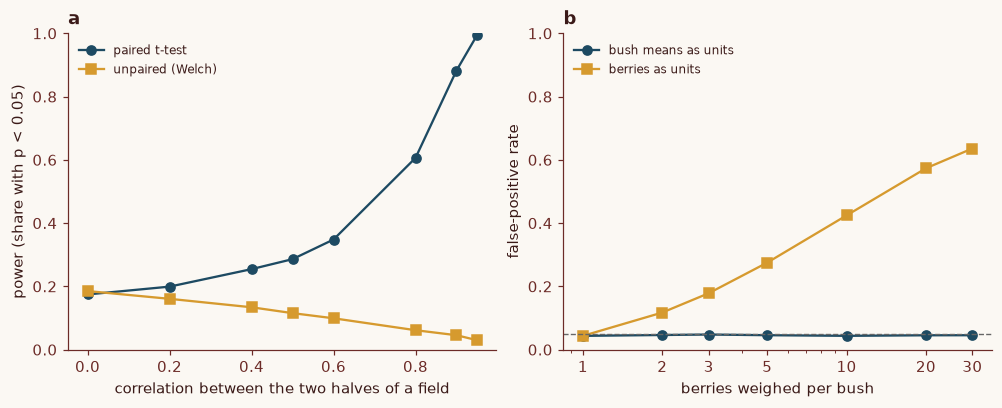

In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
a.plot(rhos, power_paired, "o-", color=C[0], label="paired t-test")
a.plot(rhos, power_unpaired, "s-", color=C[1], label="unpaired (Welch)")
a.set(xlabel="correlation between the two halves of a field", ylabel="power (share with p < 0.05)", ylim=(0, 1))
b.plot(per_bush, fp_bushes, "o-", color=C[0], label="bush means as units")
b.plot(per_bush, fp_berries, "s-", color=C[1], label="berries as units")
b.axhline(ALPHA, color="0.4", lw=0.9, ls="--")
b.set(xscale="log", xticks=per_bush, xticklabels=per_bush, xlabel="berries weighed per bush", ylabel="false-positive rate", ylim=(0, 1))
for ax, letter in ((a, "a"), (b, "b")):
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.set_title(letter, loc="left", fontweight="bold")
plt.show()

<strong>Figure 1 | Getting the unit right matters more than the choice of test.</strong> <strong>a</strong>, Power for a true effect of 0.5 SD, 10 paired fields. <strong>b</strong>, False-positive rate with no effect, 5 bushes per treatment, ICC 0.5; dashed, 5%. 20,000 synthetic experiments per point.

### Heavy tails, outliers and small samples

Normality is assumed for the *means*, which are near normal with enough units whatever the raw data look like, so failures here are milder. Below: outlier-prone data, 15 per group, and skewed lognormal data at three group sizes.

In [7]:
def contaminated(shape):  # normal with SD 1, except 10% of values have SD 10
    x = rng.normal(0, 1, shape)
    return np.where(rng.random(shape) < 0.1, 10 * x, x)


for shift in (0.0, 1.0):
    a, b = contaminated((REPS, 15)), contaminated((REPS, 15)) + shift
    print(f"outlier-prone data, n = 15 each, true shift {shift}: share p < 0.05, "
          f"Welch {share_sig(stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue):.3f}, "
          f"Mann-Whitney {share_sig(stats.mannwhitneyu(a, b, axis=1).pvalue):.3f}")

for n1, n2 in [(5, 5), (30, 30), (5, 50)]:
    a, b = rng.lognormal(0, 1, (REPS, n1)), rng.lognormal(0, 1, (REPS, n2))
    print(f"skewed data, same distribution, n = {n1} vs {n2}: Welch false positives "
          f"{share_sig(stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue):.3f}")

outlier-prone data, n = 15 each, true shift 0.0: share p < 0.05, Welch 0.022, Mann-Whitney 0.044
outlier-prone data, n = 15 each, true shift 1.0: share p < 0.05, Welch 0.237, Mann-Whitney 0.541
skewed data, same distribution, n = 5 vs 5: Welch false positives 0.022
skewed data, same distribution, n = 30 vs 30: Welch false positives 0.039


skewed data, same distribution, n = 5 vs 50: Welch false positives 0.145


Outliers do not fool Welch into false positives (2.2%); they cost power. A true shift of 1 is detected 23.7% of the time by Welch and 54.1% by the rank-based Mann–Whitney test, because a few wild values inflate the standard deviation. Skewed data with equal groups leave Welch slightly conservative, 2.2% at 5 per group and 3.9% at 30, but 5 against 50 gives 14.5%, and with 5 values a QQ plot cannot show the shape. My own rule of thumb, not a tested cut-off: below about ten units per group with skewed data such as counts, log-transform or use a rank or permutation test.

### What to use instead

The **Mann–Whitney U test**[^5] compares ranks, so outliers cannot dominate, but it asks whether one group tends to give larger values, not whether the means differ. Permutation tests, which shuffle group labels to build the null distribution, get a module of their own later.

```{mermaid}
flowchart TD
  A["Two sets of measurements"] --> B{"Same unit measured twice?"}
  B -->|"yes"| P["Paired t-test on the differences"]
  B -->|"no"| C{"Several measurements per randomised unit?"}
  C -->|"yes"| M["Average per unit, or a mixed model"]
  C -->|"no"| D{"Gross outliers, or small and skewed?"}
  D -->|"yes"| R["Mann–Whitney or a permutation test"]
  D -->|"no"| W["Welch's t-test"]
  classDef indigo fill:#1d4a62,stroke:#c97d62,stroke-width:1.5px,color:#ffffff
  classDef ochre fill:#d69a2e,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
  classDef sage fill:#95a87f,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
  class A indigo
  class B,C,D ochre
  class P,M,R,W sage
```

The cell below is the version to copy. In its synthetic draw one value in `b` is 2.71 g and the other seven are below 1.65 g (first output line), so Welch, comparing means, and Mann–Whitney, comparing ranks, disagree: $p = 0.592$ against $p = 0.039$. Plot the data before choosing.

In [8]:
# Copy this. a, b: one value per independent unit; before, after: matched by unit.
import pandas as pd
import statsmodels.formula.api as smf

a, b = rng.normal(1.6, 0.2, 12), rng.normal(1.8, 0.4, 8)  # synthetic
print("b, sorted:", np.sort(b).round(2))
before = rng.normal(2.0, 0.5, 10)
after = before + rng.normal(0.2, 0.2, 10)
print(f"Welch        p = {stats.ttest_ind(a, b, equal_var=False).pvalue:.3f}")  # default for two groups
print(f"paired       p = {stats.ttest_rel(after, before).pvalue:.3f}")          # same unit measured twice
print(f"Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3f}")                # ranks, robust to outliers

# Clustered: one row per berry, random intercept per bush (synthetic, no true effect). For real data,
# `bush` is your unit column; unequal counts per bush are fine.
# With few units MixedLM may warn that it did not converge.
berry = pd.DataFrame({"bush": np.repeat(np.arange(10), 10), "treatment": np.repeat([0, 1], 50)})
berry["weight"] = 1.8 + rng.normal(0, SD_BUSH, 10)[berry.bush] + rng.normal(0, SD_BERRY, 100)
fit = smf.mixedlm("weight ~ treatment", berry, groups="bush").fit()
between = fit.cov_re.iloc[0, 0]  # between-bush variance; fit.scale is within-bush
print(f"mixed model  p = {fit.pvalues['treatment']:.3f}, ICC = {between / (between + fit.scale):.2f} (true 0.5)")

b, sorted: [1.01 1.23 1.28 1.4  1.43 1.53 1.63 2.71]
Welch        p = 0.592
paired       p = 0.035
Mann-Whitney p = 0.039
mixed model  p = 0.567, ICC = 0.60 (true 0.5)


## Key takeaways

- Before any test, write down what was randomised: bushes, fields, lots. That count is $n$; anything measured inside one unit is a subsample.
- Write `equal_var=False` every time in scipy, and do not run a variance test to decide.
- If the design pairs measurements, pair the analysis; if it does not, do not.
- If a few values dominate, use ranks or a permutation test; do not delete points.

::: {.callout-tip}
## What this means for you

What counts as one replicate changes the answer more than which test you run, and Hurlbert's survey suggests the mistake is common[^4]. My own inference, not tested here: with few true replicates, more bushes or fields buy more than more fruit per bush. For how many units to plan for, see [Power, and how many samples](../power-and-how-many-samples.qmd).
:::

## References

[^1]: Student. The probable error of a mean. *Biometrika* **6**, 1–25 (1908). https://doi.org/10.1093/biomet/6.1.1
[^2]: Welch, B. L. The generalization of 'Student's' problem when several different population variances are involved. *Biometrika* **34**, 28–35 (1947). https://doi.org/10.1093/biomet/34.1-2.28
[^3]: Delacre, M., Lakens, D. & Leys, C. Why psychologists should by default use Welch's t-test instead of Student's t-test. *Int. Rev. Soc. Psychol.* **30**, 92–101 (2017). https://doi.org/10.5334/irsp.82
[^4]: Hurlbert, S. H. Pseudoreplication and the design of ecological field experiments. *Ecol. Monogr.* **54**, 187–211 (1984). https://doi.org/10.2307/1942661
[^5]: Mann, H. B. & Whitney, D. R. On a test of whether one of two random variables is stochastically larger than the other. *Ann. Math. Stat.* **18**, 50–60 (1947). https://doi.org/10.1214/aoms/1177730491

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/ks_test/ks_test.html"><span>Previous</span>The Kolmogorov–Smirnov test</a><a class="mf-up" href="/series/statistics/index.html"><span>Series</span>Statistics</a><a class="mf-next" href="/blogs/cross-validation/cross_validation.html"><span>Next</span>Cross-validation</a></div>
<!-- CURRICULUM_FOOTER_END -->